# 02. Análise da acessibilidade da cesta básica

## Integrante 2

### Objetivo

Analisar a evolução do custo da cesta básica em comparação
ao salário mínimo, identificando o percentual da renda
comprometido com a alimentação e as variações do poder
de compra ao longo do período analisado.

### Etapas da análise

1. Carregar e verificar os dados da cesta básica.
2. Definir a composição e calcular o custo mensal da cesta.
3. Obter o histórico do salário mínimo.
4. Calcular o comprometimento salarial.
5. Analisar a evolução do poder de compra.
6. Construir gráficos comparativos.
7. Apresentar os resultados e a conclusão.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configurações dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Identificação da raiz do projeto
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Caminhos dos arquivos
DATA = ROOT / "data/processed"
RAW = ROOT / "data/raw"
FIG = ROOT / "reports/figures"

FIG.mkdir(parents=True, exist_ok=True)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
# Caminho da base de dados mensal
ARQUIVO = DATA / "cesta_mensal.csv"

# Carregar os dados
df = pd.read_csv(ARQUIVO, parse_dates=["mes"])

# Visualizar as primeiras linhas
display(df.head())

# Verificar tamanho da base
print("Dimensões da base:", df.shape)

# Verificar nomes das colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

# Verificar tipos de dados e valores ausentes
print("\nInformações da base:")
df.info()

,mes,produto,ppk_mediana,ppk_media,n_coletas
0,2022-09-01,Arroz,4.788,4.765714,126
1,2022-09-01,Açúcar,4.390,4.696987,78
2,2022-09-01,Banana Nanica,5.990,6.143529,17
3,2022-09-01,Banana Prata,8.990,8.898000,15
4,2022-09-01,Batata,5.075,5.256429,28


Dimensões da base: (780, 5)

Colunas disponíveis:
['mes', 'produto', 'ppk_mediana', 'ppk_media', 'n_coletas']

Informações da base:
<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   mes          780 non-null    datetime64[us]
 1   produto      780 non-null    str           
 2   ppk_mediana  780 non-null    float64       
 3   ppk_media    780 non-null    float64       
 4   n_coletas    780 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 30.6 KB


In [3]:
# 1. Período analisado
print("PRIMEIRO MÊS:", df["mes"].min().strftime("%m/%Y"))
print("ÚLTIMO MÊS:", df["mes"].max().strftime("%m/%Y"))
print("TOTAL DE MESES:", df["mes"].nunique())

# 2. Produtos disponíveis
print("\nPRODUTOS DISPONÍVEIS:")
print(sorted(df["produto"].unique()))

print("\nTOTAL DE PRODUTOS:", df["produto"].nunique())

# 3. Quantidade de produtos por mês
print("\nPRODUTOS REGISTRADOS POR MÊS:")

display(
    df.groupby("mes")["produto"]
    .nunique()
    .describe()
)

# 4. Verificar registros duplicados
duplicados = df.duplicated(
    subset=["mes", "produto"]
).sum()

print("\nREGISTROS DUPLICADOS:", duplicados)

# 5. Verificar preços inválidos
invalidos = (
    ~np.isfinite(df["ppk_mediana"]) |
    (df["ppk_mediana"] <= 0)
).sum()

print("PREÇOS INVÁLIDOS:", invalidos)

# 6. Estatísticas dos preços por produto
estatisticas = (
    df.groupby("produto")["ppk_mediana"]
    .agg(["mean", "min", "max"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(estatisticas)

PRIMEIRO MÊS: 09/2022
ÚLTIMO MÊS: 08/2026
TOTAL DE MESES: 48

PRODUTOS DISPONÍVEIS:
['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Acém', 'Carne Bovina Coxão Mole', 'Carne Suína Pernil', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Manteiga', 'Ovo', 'Pão Francês', 'Tomate', 'Óleo']

TOTAL DE PRODUTOS: 20

PRODUTOS REGISTRADOS POR MÊS:


count    48.000000
mean     16.250000
std       2.935476
min      14.000000
25%      14.000000
50%      14.000000
75%      20.000000
max      20.000000
Name: produto, dtype: float64


REGISTROS DUPLICADOS: 0
PREÇOS INVÁLIDOS: 0


,mean,min,max
produto,,,
Manteiga,68.53,53.16,73.20
Café,50.16,33.70,73.98
Carne Bovina Coxão Mole,45.33,36.79,55.99
Carne Bovina Acém,40.68,37.94,43.99
Frango Peito,23.48,18.24,26.99
Carne Suína Pernil,21.62,18.99,23.99
Frango Sobrecoxa,16.89,15.48,18.49
Pão Francês,16.70,14.98,18.99
Banana Prata,10.55,7.99,12.99


In [4]:
ARQUIVO_LIMPO = DATA / "cesta_limpa.csv"

df_limpo = pd.read_csv(
    ARQUIVO_LIMPO,
    parse_dates=["mes", "data_coleta"]
)

# Verificar dimensões
print("DIMENSÕES:", df_limpo.shape)

# Verificar todas as colunas
print("\nCOLUNAS DISPONÍVEIS:")
print(df_limpo.columns.tolist())

# Verificar tipos de dados
print("\nINFORMAÇÕES:")
df_limpo.info()

# Visualizar os primeiros registros
print("\nPRIMEIROS REGISTROS:")
display(df_limpo.head(10))

# Verificar os produtos disponíveis
print("\nPRODUTOS:")
print(sorted(df_limpo["produto"].dropna().unique()))

DIMENSÕES: (44491, 8)

COLUNAS DISPONÍVEIS:
['mes', 'data_coleta', 'estab', 'produto', 'marca', 'preco', 'quantidade', 'ppk']

INFORMAÇÕES:
<class 'pandas.DataFrame'>
RangeIndex: 44491 entries, 0 to 44490
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   mes          44491 non-null  datetime64[us]
 1   data_coleta  34927 non-null  datetime64[us]
 2   estab        44491 non-null  str           
 3   produto      44491 non-null  str           
 4   marca        35321 non-null  str           
 5   preco        44491 non-null  float64       
 6   quantidade   44491 non-null  float64       
 7   ppk          44491 non-null  float64       
dtypes: datetime64[us](2), float64(3), str(3)
memory usage: 2.7 MB

PRIMEIROS REGISTROS:


,mes,data_coleta,estab,produto,marca,preco,quantidade,ppk
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1.0,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1.0,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1.0,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1.0,46.90



PRODUTOS:
['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Acém', 'Carne Bovina Coxão Mole', 'Carne Suína Pernil', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Manteiga', 'Ovo', 'Pão Francês', 'Tomate', 'Óleo']


In [5]:
# Carregar a base limpa
ARQUIVO_LIMPO = DATA / "cesta_limpa.csv"

df_limpo = pd.read_csv(
    ARQUIVO_LIMPO,
    parse_dates=["mes", "data_coleta"]
)

# Verificar dimensões
print("DIMENSÕES:", df_limpo.shape)

# Verificar todas as colunas
print("\nCOLUNAS DISPONÍVEIS:")
print(df_limpo.columns.tolist())

# Verificar tipos de dados
print("\nINFORMAÇÕES:")
df_limpo.info()

# Visualizar os primeiros registros
print("\nPRIMEIROS REGISTROS:")
display(df_limpo.head(10))

# Verificar os produtos disponíveis
print("\nPRODUTOS:")
print(sorted(df_limpo["produto"].dropna().unique()))

DIMENSÕES: (44491, 8)

COLUNAS DISPONÍVEIS:
['mes', 'data_coleta', 'estab', 'produto', 'marca', 'preco', 'quantidade', 'ppk']

INFORMAÇÕES:
<class 'pandas.DataFrame'>
RangeIndex: 44491 entries, 0 to 44490
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   mes          44491 non-null  datetime64[us]
 1   data_coleta  34927 non-null  datetime64[us]
 2   estab        44491 non-null  str           
 3   produto      44491 non-null  str           
 4   marca        35321 non-null  str           
 5   preco        44491 non-null  float64       
 6   quantidade   44491 non-null  float64       
 7   ppk          44491 non-null  float64       
dtypes: datetime64[us](2), float64(3), str(3)
memory usage: 2.7 MB

PRIMEIROS REGISTROS:


,mes,data_coleta,estab,produto,marca,preco,quantidade,ppk
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1.0,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1.0,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1.0,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1.0,46.90



PRODUTOS:
['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Acém', 'Carne Bovina Coxão Mole', 'Carne Suína Pernil', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Manteiga', 'Ovo', 'Pão Francês', 'Tomate', 'Óleo']


In [6]:
# 1. Listar todas as quantidades encontradas por produto

print("QUANTIDADES DISTINTAS POR PRODUTO:\n")

for produto in sorted(df_limpo["produto"].unique()):
    quantidades = sorted(
        df_limpo.loc[
            df_limpo["produto"] == produto,
            "quantidade"
        ].dropna().unique()
    )

    print(f"{produto}: {[float(q) for q in quantidades]}")


# 2. Investigar o arquivo original

print("\nARQUIVO ORIGINAL:")

arquivo = RAW / "ICB_DADOS_2026.xlsx"

if arquivo.exists():

    print(f"Arquivo encontrado: {arquivo.name}")

    original = pd.read_excel(arquivo, nrows=5)

    print("Colunas:", original.columns.tolist())

    display(original.head())

else:
    print("Arquivo não encontrado.")
    print("Caminho procurado:", arquivo)

QUANTIDADES DISTINTAS POR PRODUTO:

Arroz: [1.0, 2.0, 5.0]
Açúcar: [0.5, 1.0, 2.0, 3.0]
Banana Nanica: [0.7, 1.0]
Banana Prata: [1.0]
Batata: [1.0]
Café: [0.25, 0.5, 1.0]
Carne Bovina Acém: [1.0]
Carne Bovina Coxão Mole: [1.0]
Carne Suína Pernil: [0.32, 1.0]
Farinha de Trigo: [0.5, 1.0, 3.0]
Feijão: [1.0, 3.0]
Frango Peito: [0.53, 1.0]
Frango Sobrecoxa: [1.0]
Leite: [1.0]
Macarrão: [0.5, 1.0]
Manteiga: [0.2, 0.25, 0.35, 0.38, 0.4, 0.5, 1.0]
Ovo: [10.0, 12.0, 20.0, 30.0, 60.0]
Pão Francês: [1.0]
Tomate: [1.0]
Óleo: [0.9, 1.0]

ARQUIVO ORIGINAL:
Arquivo encontrado: ICB_DADOS_2026.xlsx
Colunas: ['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco', 'Quantidade', 'PPK']


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1,51.90


In [7]:
# Listar todos os arquivos da pasta data

PASTA_DATA = ROOT / "data"

print("ARQUIVOS ENCONTRADOS:\n")

for arquivo in sorted(PASTA_DATA.rglob("*")):
    if arquivo.is_file():
        print(
            f"Nome: {arquivo.name} | "
            f"Extensão: {arquivo.suffix} | "
            f"Caminho: {arquivo.relative_to(ROOT)}"
        )

ARQUIVOS ENCONTRADOS:

Nome: .gitkeep | Extensão:  | Caminho: data/processed/.gitkeep
Nome: cesta_limpa.csv | Extensão: .csv | Caminho: data/processed/cesta_limpa.csv
Nome: cesta_limpa_completa.csv | Extensão: .csv | Caminho: data/processed/cesta_limpa_completa.csv
Nome: cesta_mensal.csv | Extensão: .csv | Caminho: data/processed/cesta_mensal.csv
Nome: comparacao_baseline.csv | Extensão: .csv | Caminho: data/processed/comparacao_baseline.csv
Nome: estatisticas_descritivas.csv | Extensão: .csv | Caminho: data/processed/estatisticas_descritivas.csv
Nome: melhores_modelos.csv | Extensão: .csv | Caminho: data/processed/melhores_modelos.csv
Nome: melhores_periodos_compra.csv | Extensão: .csv | Caminho: data/processed/melhores_periodos_compra.csv
Nome: melhores_periodos_futuros.csv | Extensão: .csv | Caminho: data/processed/melhores_periodos_futuros.csv
Nome: melhores_periodos_historicos.csv | Extensão: .csv | Caminho: data/processed/melhores_periodos_historicos.csv
Nome: melhores_periodos_r

In [8]:
# Caminho do arquivo original
ARQUIVO_ORIGINAL = RAW / "ICB_DADOS_2026.xlsx"

# Identificar as planilhas existentes
excel = pd.ExcelFile(ARQUIVO_ORIGINAL)

print("PLANILHAS DISPONÍVEIS:")
print(excel.sheet_names)

# Examinar cada planilha
for planilha in excel.sheet_names:

    print(f"\n{'='*60}")
    print(f"PLANILHA: {planilha}")
    print(f"{'='*60}")

    dados = pd.read_excel(
        ARQUIVO_ORIGINAL,
        sheet_name=planilha,
        nrows=10
    )

    print("COLUNAS:")
    print(dados.columns.tolist())

    print("\nPRIMEIROS REGISTROS:")
    display(dados.head(10))

PLANILHAS DISPONÍVEIS:
['ACUMUL_DESAGREG']

PLANILHA: ACUMUL_DESAGREG
COLUNAS:
['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco', 'Quantidade', 'PPK']

PRIMEIROS REGISTROS:


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1,46.90


In [9]:
composicao_diese = pd.DataFrame({
    "alimento": [
        "Carne",
        "Leite",
        "Feijão",
        "Arroz",
        "Farinha",
        "Batata",
        "Tomate",
        "Pão francês",
        "Café",
        "Banana",
        "Açúcar",
        "Óleo",
        "Manteiga"
    ],
    "quantidade_mensal": [
        6.0, 7.5, 4.5, 3.0, 1.5, 6.0, 9.0,
        6.0, 0.6, 90, 3.0, 0.75, 0.75
    ],
    "unidade": [
        "kg", "litros", "kg", "kg", "kg", "kg", "kg",
        "kg", "kg", "unidades", "kg", "kg", "kg"
    ]
})

display(composicao_diese)

,alimento,quantidade_mensal,unidade
0,Carne,6.00,kg
1,Leite,7.50,litros
2,Feijão,4.50,kg
3,Arroz,3.00,kg
4,Farinha,1.50,kg
5,Batata,6.00,kg
6,Tomate,9.00,kg
7,Pão francês,6.00,kg
8,Café,0.60,kg
9,Banana,90.00,unidades


In [10]:
produtos_base = sorted(df["produto"].dropna().unique())

print("PRODUTOS DISPONÍVEIS NA BASE:\n")

for produto in produtos_base:
    print("-", produto)

PRODUTOS DISPONÍVEIS NA BASE:

- Arroz
- Açúcar
- Banana Nanica
- Banana Prata
- Batata
- Café
- Carne Bovina Acém
- Carne Bovina Coxão Mole
- Carne Suína Pernil
- Farinha de Trigo
- Feijão
- Frango Peito
- Frango Sobrecoxa
- Leite
- Macarrão
- Manteiga
- Ovo
- Pão Francês
- Tomate
- Óleo


In [11]:
correspondencia = {
    "Carne": ["Carne Bovina Coxão Mole"],
    "Leite": ["Leite"],
    "Feijão": ["Feijão"],
    "Arroz": ["Arroz"],
    "Farinha": ["Farinha de Trigo"],
    "Batata": ["Batata"],
    "Tomate": ["Tomate"],
    "Pão francês": ["Pão Francês"],
    "Café": ["Café"],
    "Banana": ["Banana Nanica", "Banana Prata"],
    "Açúcar": ["Açúcar"],
    "Óleo": ["Óleo"],
    "Manteiga": ["Manteiga"]
}

diagnostico = []

for alimento, produtos in correspondencia.items():
    for produto in produtos:
        dados = df_limpo[df_limpo["produto"] == produto]

        diagnostico.append({
            "Alimento": alimento,
            "Produto na base": produto,
            "Registros": len(dados),
            "Meses disponíveis": dados["mes"].nunique(),
            "Quantidades encontradas": sorted(
                dados["quantidade"].dropna().unique().tolist()
            )
        })

diagnostico_df = pd.DataFrame(diagnostico)

display(diagnostico_df)

,Alimento,Produto na base,Registros,Meses disponíveis,Quantidades encontradas
0,Carne,Carne Bovina Coxão Mole,1195,48,[1.0]
1,Leite,Leite,4463,48,[1.0]
2,Feijão,Feijão,4596,48,"[1.0, 3.0]"
3,Arroz,Arroz,5076,48,"[1.0, 2.0, 5.0]"
4,Farinha,Farinha de Trigo,4105,48,"[0.5, 1.0, 3.0]"
5,Batata,Batata,1283,48,[1.0]
6,Tomate,Tomate,1288,48,[1.0]
7,Pão francês,Pão Francês,1033,48,[1.0]
8,Café,Café,5171,48,"[0.25, 0.5, 1.0]"
9,Banana,Banana Nanica,1176,48,"[0.7, 1.0]"


In [12]:
produtos_para_conferir = [
    "Arroz",
    "Café",
    "Farinha de Trigo",
    "Banana Nanica",
    "Banana Prata",
    "Açúcar",
    "Leite",
    "Óleo",
    "Manteiga"
]

for produto in produtos_para_conferir:
    print(f"\n--- {produto} ---")

    dados = df_limpo[df_limpo["produto"] == produto]

    amostras = (
        dados.groupby("quantidade")
        .agg(
            registros=("preco", "size"),
            preco_mediano=("preco", "median"),
            ppk_mediano=("ppk", "median")
        )
        .reset_index()
        .sort_values("quantidade")
        .round(2)
    )

    display(amostras)


--- Arroz ---


,quantidade,registros,preco_mediano,ppk_mediano
0,1.0,4,5.98,5.98
1,2.0,13,11.60,5.80
2,5.0,5059,28.59,5.72



--- Café ---


,quantidade,registros,preco_mediano,ppk_mediano
0,0.25,2,15.20,60.78
1,0.50,5161,21.99,43.98
2,1.00,8,29.92,29.92



--- Farinha de Trigo ---


,quantidade,registros,preco_mediano,ppk_mediano
0,0.5,2,6.14,12.28
1,1.0,4101,5.89,5.89
2,3.0,2,5.84,1.95


... (8 outputs left out)


--- Óleo ---


,quantidade,registros,preco_mediano,ppk_mediano
0,0.9,3042,7.50,8.33
1,1.0,8,8.69,8.69



--- Manteiga ---


,quantidade,registros,preco_mediano,ppk_mediano
0,0.20,4509,13.95,69.75
1,0.25,52,12.79,51.16
2,0.35,1,22.90,65.43
3,0.38,8,22.90,60.26
4,0.40,1,16.85,42.12
5,0.50,81,27.99,55.98
6,1.00,1,16.55,16.55


In [13]:
produtos_cesta = [
    "Carne Bovina Coxão Mole",
    "Leite",
    "Feijão",
    "Arroz",
    "Farinha de Trigo",
    "Batata",
    "Tomate",
    "Pão Francês",
    "Café",
    "Banana Nanica",
    "Banana Prata",
    "Açúcar",
    "Óleo",
    "Manteiga"
]

resumo_precos = (
    df_limpo[df_limpo["produto"].isin(produtos_cesta)]
    .groupby("produto")
    .agg(
        registros=("ppk", "count"),
        preco_minimo=("preco", "min"),
        preco_medio=("preco", "mean"),
        preco_maximo=("preco", "max"),
        ppk_minimo=("ppk", "min"),
        ppk_medio=("ppk", "mean"),
        ppk_mediano=("ppk", "median"),
        ppk_maximo=("ppk", "max")
    )
    .round(2)
)

display(resumo_precos)

,registros,preco_minimo,preco_medio,preco_maximo,ppk_minimo,ppk_medio,ppk_mediano,ppk_maximo
produto,,,,,,,,
Arroz,5076,4.75,28.53,47.99,1.20,5.72,5.73,9.60
Açúcar,2986,2.19,4.50,22.20,1.53,4.50,4.45,22.20
Banana Nanica,1176,1.95,6.57,18.99,1.95,6.57,6.72,18.99
Banana Prata,1171,2.99,10.57,19.99,2.99,10.57,10.00,19.99
Batata,1283,1.49,6.52,15.99,1.49,6.52,5.99,15.99
Café,5171,6.89,24.57,48.99,13.78,49.10,43.98,97.98
Carne Bovina Coxão Mole,1195,19.90,45.20,65.65,19.90,45.20,45.90,65.65
Farinha de Trigo,4105,2.29,5.96,13.99,1.83,5.96,5.89,13.99
Feijão,4596,2.49,8.36,13.99,2.49,8.36,8.39,13.99


In [14]:
# Carregar a base mensal
ARQUIVO_MENSAL = DATA / "cesta_mensal.csv"

df_mensal = pd.read_csv(
    ARQUIVO_MENSAL,
    parse_dates=["mes"]
)

print("Base mensal carregada!")
print("Dimensões:", df_mensal.shape)

display(df_mensal.head())

Base mensal carregada!
Dimensões: (780, 5)


,mes,produto,ppk_mediana,ppk_media,n_coletas
0,2022-09-01,Arroz,4.788,4.765714,126
1,2022-09-01,Açúcar,4.390,4.696987,78
2,2022-09-01,Banana Nanica,5.990,6.143529,17
3,2022-09-01,Banana Prata,8.990,8.898000,15
4,2022-09-01,Batata,5.075,5.256429,28


In [15]:
# Verificar o período da base mensal

print("Primeiro mês:", df_mensal["mes"].min().strftime("%m/%Y"))

print("Último mês:", df_mensal["mes"].max().strftime("%m/%Y"))

print("Quantidade de meses:", df_mensal["mes"].nunique())

Primeiro mês: 09/2022
Último mês: 08/2026
Quantidade de meses: 48


In [16]:
display(
    df_mensal[
        ["mes", "produto", "ppk_mediana", "n_coletas"]
    ].head(15)
)

,mes,produto,ppk_mediana,n_coletas
0,2022-09-01,Arroz,4.788000,126
1,2022-09-01,Açúcar,4.390000,78
2,2022-09-01,Banana Nanica,5.990000,17
3,2022-09-01,Banana Prata,8.990000,15
4,2022-09-01,Batata,5.075000,28
5,2022-09-01,Café,37.980000,133
6,2022-09-01,Carne Bovina Coxão Mole,45.900000,27
7,2022-09-01,Farinha de Trigo,6.250000,97
8,2022-09-01,Feijão,8.990000,98
9,2022-09-01,Leite,5.790000,102


In [17]:
composicao = pd.DataFrame({
    "produto": [
        "Carne Bovina Coxão Mole",
        "Leite",
        "Feijão",
        "Arroz",
        "Farinha de Trigo",
        "Batata",
        "Tomate",
        "Pão Francês",
        "Café",
        "Açúcar",
        "Óleo",
        "Manteiga"
    ],
    "quantidade_mensal": [
        6.0, 7.5, 4.5, 3.0, 1.5, 6.0,
        9.0, 6.0, 0.6, 3.0, 0.75, 0.75
    ],
    "unidade_referencia": [
        "kg", "litros", "kg", "kg", "kg", "kg",
        "kg", "kg", "kg", "kg", "kg", "kg"
    ]
})

display(composicao)

,produto,quantidade_mensal,unidade_referencia
0,Carne Bovina Coxão Mole,6.00,kg
1,Leite,7.50,litros
2,Feijão,4.50,kg
3,Arroz,3.00,kg
4,Farinha de Trigo,1.50,kg
5,Batata,6.00,kg
6,Tomate,9.00,kg
7,Pão Francês,6.00,kg
8,Café,0.60,kg
9,Açúcar,3.00,kg


In [18]:
# Conversões utilizadas na estimativa da cesta

# Banana: peso de uma dúzia
peso_duzia_nanica = 1.8
peso_duzia_prata = 1.2

# DIEESE: 90 bananas = 7,5 dúzias
duzias_banana = 90 / 12

# Quantidade equivalente em kg
banana_nanica_kg = duzias_banana * peso_duzia_nanica
banana_prata_kg = duzias_banana * peso_duzia_prata

# Óleo: conversão de 750 g para litros
densidade_oleo = 0.922  # kg/L
oleo_litros = 0.750 / densidade_oleo

print("CONVERSÕES ESTIMADAS DA CESTA")
print(f"Banana Nanica: {banana_nanica_kg:.2f} kg")
print(f"Banana Prata: {banana_prata_kg:.2f} kg")
print(f"Óleo: {oleo_litros:.3f} litros")

CONVERSÕES ESTIMADAS DA CESTA
Banana Nanica: 13.50 kg
Banana Prata: 9.00 kg
Óleo: 0.813 litros


In [19]:
produtos_cesta = composicao["produto"].tolist()

disponiveis = sorted(df_mensal["produto"].unique())

total_meses = df_mensal["mes"].nunique()

for produto in produtos_cesta:
    meses = df_mensal.loc[
        df_mensal["produto"] == produto, "mes"
    ].nunique()

    if produto in disponiveis:
        print(f"OK - {produto}: {meses}/{total_meses} meses")
    else:
        print(f"FALTA - {produto}")

print("\nBananas:")

for produto in ["Banana Nanica", "Banana Prata"]:
    meses = df_mensal.loc[
        df_mensal["produto"] == produto, "mes"
    ].nunique()

    if produto in disponiveis:
        print(f"OK - {produto}: {meses}/{total_meses} meses")
    else:
        print(f"FALTA - {produto}")

OK - Carne Bovina Coxão Mole: 48/48 meses
OK - Leite: 48/48 meses
OK - Feijão: 48/48 meses
OK - Arroz: 48/48 meses
OK - Farinha de Trigo: 48/48 meses
OK - Batata: 48/48 meses
OK - Tomate: 48/48 meses
OK - Pão Francês: 48/48 meses
OK - Café: 48/48 meses
OK - Açúcar: 48/48 meses
OK - Óleo: 48/48 meses
OK - Manteiga: 48/48 meses

Bananas:
OK - Banana Nanica: 48/48 meses
OK - Banana Prata: 48/48 meses


In [20]:
# Produtos que fazem parte da nossa análise da cesta
produtos_cesta = composicao["produto"].tolist() + [
    "Banana Nanica",
    "Banana Prata"
]

# Criar tabela de cobertura mensal dos produtos
cobertura = (
    df_mensal[df_mensal["produto"].isin(produtos_cesta)]
    .pivot(
        index="mes",
        columns="produto",
        values="ppk_mediana"
    )
    .reindex(
        index=pd.date_range(
            start=df_mensal["mes"].min(),
            end=df_mensal["mes"].max(),
            freq="MS"
        ),
        columns=produtos_cesta
    )
)

cobertura.index.name = "mes"

# Verificar quantos produtos estão disponíveis em cada mês
cobertura["total_produtos"] = (
    cobertura[produtos_cesta].notna().sum(axis=1)
)

display(cobertura)

print("Menor quantidade de produtos em um mês:",
      cobertura["total_produtos"].min())

print("Maior quantidade de produtos em um mês:",
      cobertura["total_produtos"].max())

print("Meses com todos os produtos:",
      (cobertura["total_produtos"] == len(produtos_cesta)).sum())

print("Meses com produtos faltantes:",
      (cobertura["total_produtos"] < len(produtos_cesta)).sum())

produto,Carne Bovina Coxão Mole,Leite,Feijão,Arroz,Farinha de Trigo,Batata,Tomate,Pão Francês,Café,Açúcar,Óleo,Manteiga,Banana Nanica,Banana Prata,total_produtos
mes,,,,,,,,,,,,,,,
2022-09-01,45.900,5.790,8.990,4.788,6.250,5.075,4.990,14.985,37.98,4.390,9.433333,53.160,5.99,8.990,14
2022-10-01,44.480,5.485,8.590,4.980,5.990,6.190,6.990,15.950,38.77,3.990,9.211111,64.225,6.59,8.590,14
2022-11-01,43.980,4.890,8.980,4.869,6.250,6.490,8.990,14.990,39.08,3.990,9.055556,67.500,6.54,7.990,14
2022-12-01,45.900,4.790,9.095,4.998,6.290,6.980,9.990,15.445,39.50,3.990,9.200000,67.950,5.89,8.140,14
2023-01-01,45.895,4.890,9.690,5.079,6.190,7.990,9.900,15.950,37.98,3.990,9.500000,67.950,5.29,8.990,14
2023-02-01,44.400,4.990,9.490,5.179,6.190,4.990,7.990,15.950,37.28,3.990,9.322222,66.950,4.59,9.980,14
2023-03-01,43.440,4.990,9.590,5.100,6.190,5.490,7.990,15.925,37.29,3.950,8.766667,64.950,5.89,9.490,14
2023-04-01,42.340,5.690,9.890,4.998,5.990,5.990,9.900,15.950,35.98,3.990,8.300000,65.450,5.49,9.890,14
2023-05-01,43.485,5.490,9.790,5.149,6.290,5.985,9.900,15.965,37.80,4.090,7.722222,69.725,5.99,8.990,14


Menor quantidade de produtos em um mês: 14
Maior quantidade de produtos em um mês: 14
Meses com todos os produtos: 48
Meses com produtos faltantes: 0


In [21]:
# Quantidades mensais utilizadas no cálculo da cesta
quantidades = composicao.set_index("produto")[
    "quantidade_mensal"
].to_dict()

# Utilizar a conversão estimada do óleo
quantidades["Óleo"] = oleo_litros

# Transformar os preços mensais em uma tabela
precos_mensais = df_mensal.pivot(
    index="mes",
    columns="produto",
    values="ppk_mediana"
).sort_index()

# Verificar se existem preços faltantes
if precos_mensais[produtos_cesta].isna().any().any():
    raise ValueError("Existem preços faltantes nos produtos da cesta.")

# Calcular o custo dos produtos que não são banana
custo_base = sum(
    precos_mensais[produto] * quantidade
    for produto, quantidade in quantidades.items()
)

# Calcular os dois cenários de banana separadamente
custo_nanica = custo_base + (
    precos_mensais["Banana Nanica"] * banana_nanica_kg
)

custo_prata = custo_base + (
    precos_mensais["Banana Prata"] * banana_prata_kg
)

# Organizar os resultados
resultado_cesta = pd.DataFrame({
    "mes": precos_mensais.index,
    "custo_sem_banana": custo_base.values,
    "cesta_banana_nanica": custo_nanica.values,
    "cesta_banana_prata": custo_prata.values
})

display(resultado_cesta.round(2))

print("Dimensões:", resultado_cesta.shape)

/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88681/4047288240.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(resultado_cesta.round(2))


,mes,custo_sem_banana,cesta_banana_nanica,cesta_banana_prata
0,2022-09-01,631.79,712.66,712.70
1,2022-10-01,657.24,746.21,734.55
2,2022-11-01,668.15,756.44,740.06
3,2022-12-01,695.26,774.77,768.52
4,2023-01-01,706.36,777.78,787.27
5,2023-02-01,661.04,723.00,750.86
6,2023-03-01,656.27,735.79,741.68
7,2023-04-01,675.34,749.45,764.35
8,2023-05-01,685.35,766.21,766.26
9,2023-06-01,685.18,766.05,766.09


Dimensões: (48, 4)


In [22]:
# Colunas que representam os três cenários
cenarios = [
    "custo_sem_banana",
    "cesta_banana_nanica",
    "cesta_banana_prata"
]

# Nomes para apresentação dos resultados
nomes_cenarios = {
    "custo_sem_banana": "Cesta sem banana (referência parcial)",
    "cesta_banana_nanica": "Cesta com Banana Nanica",
    "cesta_banana_prata": "Cesta com Banana Prata"
}

# Calcular estatísticas de cada cenário
for coluna in cenarios:
    print(f"\n{'='*45}")
    print(nomes_cenarios[coluna].upper())
    print(f"{'='*45}")

    indice_min = resultado_cesta[coluna].idxmin()
    indice_max = resultado_cesta[coluna].idxmax()

    print(
        "Menor custo:",
        f"R$ {resultado_cesta.loc[indice_min, coluna]:.2f}",
        "-",
        resultado_cesta.loc[indice_min, "mes"].strftime("%m/%Y")
    )

    print(
        "Maior custo:",
        f"R$ {resultado_cesta.loc[indice_max, coluna]:.2f}",
        "-",
        resultado_cesta.loc[indice_max, "mes"].strftime("%m/%Y")
    )

    print(f"Custo médio: R$ {resultado_cesta[coluna].mean():.2f}")

    custo_inicial = resultado_cesta[coluna].iloc[0]
    custo_final = resultado_cesta[coluna].iloc[-1]

    print(f"Custo inicial: R$ {custo_inicial:.2f}")
    print(f"Custo final: R$ {custo_final:.2f}")

    variacao = (custo_final / custo_inicial - 1) * 100

    print(f"Variação nominal no período: {variacao:.2f}%")


CESTA SEM BANANA (REFERÊNCIA PARCIAL)
Menor custo: R$ 612.75 - 09/2023
Maior custo: R$ 846.53 - 06/2026
Custo médio: R$ 696.11
Custo inicial: R$ 631.79
Custo final: R$ 769.56
Variação nominal no período: 21.81%

CESTA COM BANANA NANICA
Menor custo: R$ 706.58 - 09/2023
Maior custo: R$ 939.54 - 06/2026
Custo médio: R$ 784.73
Custo inicial: R$ 712.66
Custo final: R$ 863.92
Variação nominal no período: 21.23%

CESTA COM BANANA PRATA
Menor custo: R$ 693.66 - 09/2023
Maior custo: R$ 936.44 - 06/2026
Custo médio: R$ 791.07
Custo inicial: R$ 712.70
Custo final: R$ 877.06
Variação nominal no período: 23.06%


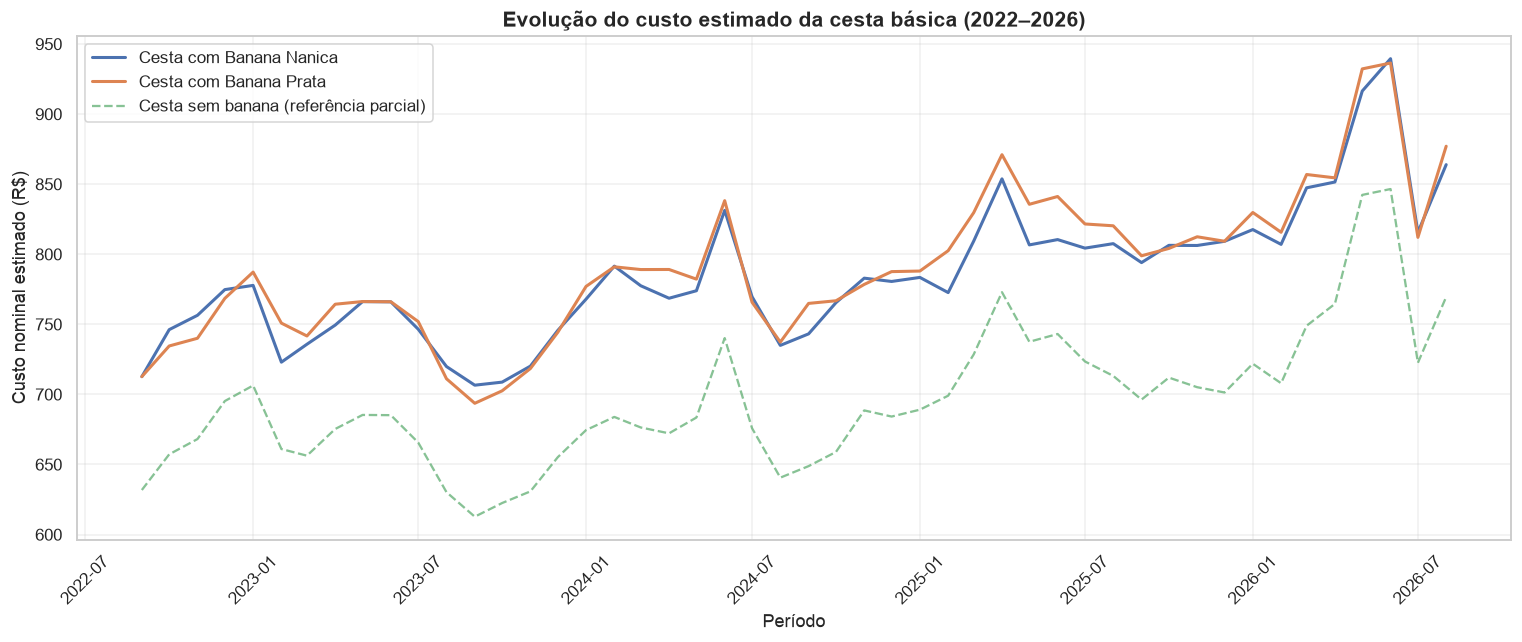

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["cesta_banana_nanica"],
    label="Cesta com Banana Nanica",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["cesta_banana_prata"],
    label="Cesta com Banana Prata",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["custo_sem_banana"],
    label="Cesta sem banana (referência parcial)",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Evolução do custo estimado da cesta básica (2022–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Período")
plt.ylabel("Custo nominal estimado (R$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIG / "evolucao_custo_cesta.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Interpretação da evolução do custo da cesta básica

Entre setembro de 2022 e agosto de 2026, observa-se uma
tendência geral de crescimento nominal do custo estimado
da cesta básica, apesar das oscilações ao longo do período.

A cesta com Banana Nanica apresentou um aumento de 21,23%,
passando de R$ 712,66 para R$ 863,92. Já a cesta com Banana
Prata apresentou um aumento de 23,06%, passando de
R$ 712,70 para R$ 877,06.

Os dois cenários apresentaram seus menores custos em
setembro de 2023 e seus maiores custos em junho de 2026.

A cesta com Banana Prata apresentou um custo médio mensal
de R$ 791,07, enquanto a cesta com Banana Nanica apresentou
um custo médio de R$ 784,73, considerando as hipóteses
de conversão adotadas.

A curva sem banana representa uma referência parcial,
permitindo observar a evolução do custo dos demais
12 alimentos.

Entretanto, o aumento nominal dos preços não significa
necessariamente uma redução do poder de compra.
Para avaliar a acessibilidade da cesta básica, é necessário
comparar sua evolução com o salário mínimo vigente
em cada mês.

In [24]:
# Salário mínimo nacional vigente em cada período
# Fonte: Ministério da Previdência Social (AEPS)
# Decreto nº 12.797/2025 para o salário de 2026

condicoes = [
    resultado_cesta["mes"] < "2023-01-01",
    resultado_cesta["mes"] < "2023-05-01",
    resultado_cesta["mes"] < "2024-01-01",
    resultado_cesta["mes"] < "2025-01-01",
    resultado_cesta["mes"] < "2026-01-01",
    resultado_cesta["mes"] < "2027-01-01"
]

valores = [
    1212.00,
    1302.00,
    1320.00,
    1412.00,
    1518.00,
    1621.00
]

resultado_cesta["salario_minimo"] = np.select(
    condicoes,
    valores,
    default=np.nan
)

# Verificar se todos os meses possuem salário definido
if resultado_cesta["salario_minimo"].isna().any():
    raise ValueError("Existem meses sem salário mínimo definido.")

# Salário líquido estimado considerando somente o INSS
aliquota_inss = 0.075

resultado_cesta["salario_liquido"] = (
    resultado_cesta["salario_minimo"] * (1 - aliquota_inss)
)

# Conferir todos os valores de salário utilizados
display(
    resultado_cesta[
        ["salario_minimo", "salario_liquido"]
    ].drop_duplicates().reset_index(drop=True).round(2)
)

,salario_minimo,salario_liquido
0,1212.0,1121.10
1,1302.0,1204.35
2,1320.0,1221.00
3,1412.0,1306.10
4,1518.0,1404.15
5,1621.0,1499.43


### Salário mínimo utilizado na análise

Foram utilizados os valores oficiais do salário mínimo
nacional vigentes em cada mês do período analisado,
incluindo o reajuste ocorrido em maio de 2023.

O salário líquido foi estimado considerando apenas
o desconto de 7,5% referente à contribuição ao INSS
de um empregado que recebe um salário mínimo.

Outros descontos e benefícios trabalhistas não foram
considerados.

Fontes:
- Ministério da Previdência Social — Anuário Estatístico
  da Previdência Social (AEPS).
- Decreto nº 12.797, de 23 de dezembro de 2025.
- INSS — Tabela de contribuição mensal.

In [25]:
# Jornada mensal de referência utilizada pelo DIEESE
jornada_mensal = 220

# Calcular os indicadores de acessibilidade
for cenario in cenarios:

    # Percentual do salário líquido comprometido
    resultado_cesta[f"comprometimento_{cenario}"] = (
        resultado_cesta[cenario] /
        resultado_cesta["salario_liquido"]
    ) * 100

    # Horas de trabalho necessárias
    resultado_cesta[f"horas_{cenario}"] = (
        resultado_cesta[cenario] * jornada_mensal /
        resultado_cesta["salario_minimo"]
    )

    # Salário líquido restante após comprar a cesta
    resultado_cesta[f"restante_{cenario}"] = (
        resultado_cesta["salario_liquido"] -
        resultado_cesta[cenario]
    )
# Exibir os primeiros 12 meses
tabela = resultado_cesta[
    [
        "mes",
        "salario_minimo",
        "cesta_banana_nanica",
        "comprometimento_cesta_banana_nanica",
        "horas_cesta_banana_nanica",
        "cesta_banana_prata",
        "comprometimento_cesta_banana_prata",
        "horas_cesta_banana_prata"
    ]
].head(12).copy()

tabela["mes"] = tabela["mes"].dt.strftime("%m/%Y")

display(tabela.round(2))

,mes,salario_minimo,cesta_banana_nanica,comprometimento_cesta_banana_nanica,horas_cesta_banana_nanica,cesta_banana_prata,comprometimento_cesta_banana_prata,horas_cesta_banana_prata
0,09/2022,1212.0,712.66,63.57,129.36,712.70,63.57,129.37
1,10/2022,1212.0,746.21,66.56,135.45,734.55,65.52,133.33
2,11/2022,1212.0,756.44,67.47,137.31,740.06,66.01,134.33
3,12/2022,1212.0,774.77,69.11,140.64,768.52,68.55,139.50
4,01/2023,1302.0,777.78,64.58,131.42,787.27,65.37,133.03
5,02/2023,1302.0,723.00,60.03,122.17,750.86,62.35,126.87
6,03/2023,1302.0,735.79,61.09,124.33,741.68,61.58,125.32
7,04/2023,1302.0,749.45,62.23,126.64,764.35,63.47,129.15
8,05/2023,1320.0,766.21,62.75,127.70,766.26,62.76,127.71
9,06/2023,1320.0,766.05,62.74,127.67,766.09,62.74,127.68


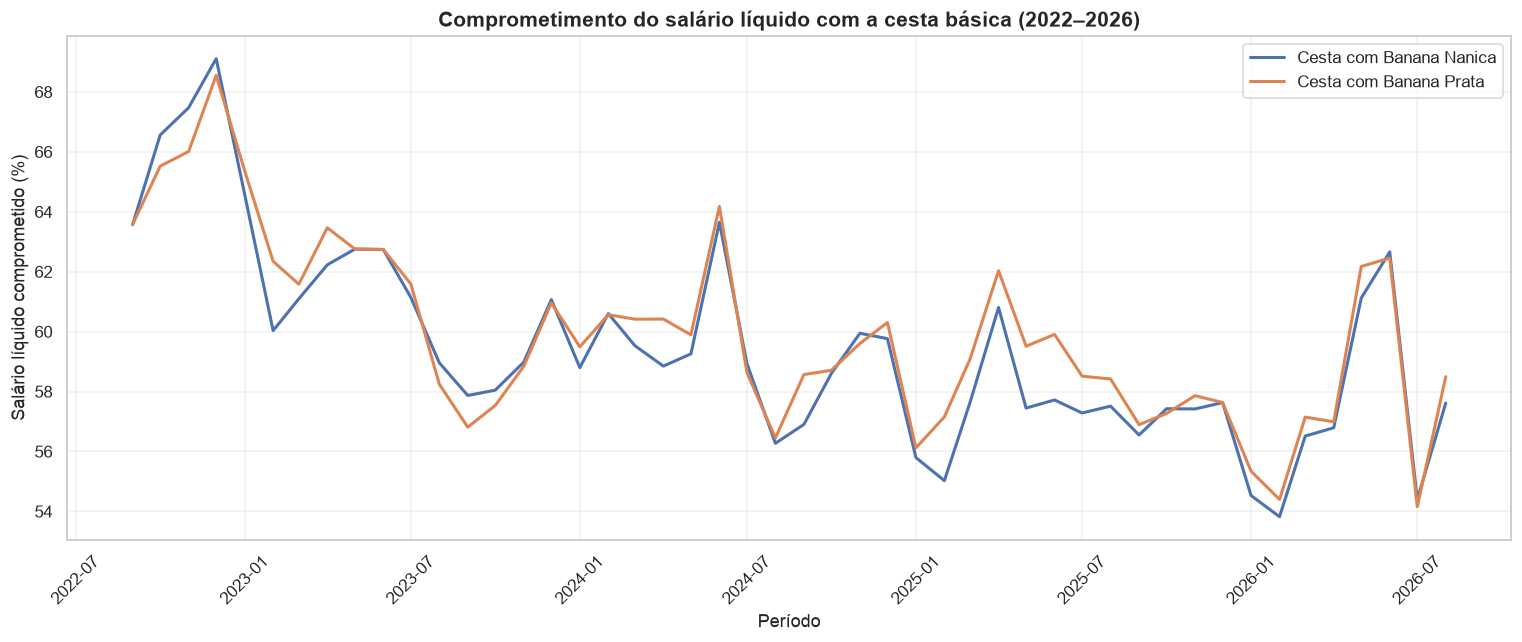

In [26]:
plt.figure(figsize=(14, 6))

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["comprometimento_cesta_banana_nanica"],
    label="Cesta com Banana Nanica",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["comprometimento_cesta_banana_prata"],
    label="Cesta com Banana Prata",
    linewidth=2
)

plt.title(
    "Comprometimento do salário líquido com a cesta básica (2022–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Período")
plt.ylabel("Salário líquido comprometido (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIG / "comprometimento_mensal.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Interpretação do comprometimento salarial

Entre setembro de 2022 e agosto de 2026, observa-se uma
tendência geral de redução do percentual do salário líquido
comprometido com a aquisição da cesta básica.

Em setembro de 2022, os dois cenários comprometiam
aproximadamente 63,57% do salário líquido.

Em agosto de 2026, esse percentual passou para aproximadamente
57,62% no cenário com Banana Nanica e 58,49% no cenário
com Banana Prata.

Essa redução indica que o salário mínimo cresceu
proporcionalmente mais do que o custo estimado da cesta
básica entre o início e o final do período.

Entretanto, ainda são observadas oscilações importantes,
especialmente no final de 2022 e entre maio e junho de 2026.

Apesar da melhora relativa na acessibilidade, a aquisição
da cesta básica ainda compromete mais da metade do salário
líquido, limitando os recursos disponíveis para outras
despesas essenciais, como moradia, transporte e energia.

Os resultados devem ser interpretados considerando as
hipóteses de conversão das unidades e a estimativa
do salário líquido adotadas neste estudo.

In [27]:
# Resumo do comprometimento salarial nos dois cenários

colunas = {
    "Banana Nanica": "comprometimento_cesta_banana_nanica",
    "Banana Prata": "comprometimento_cesta_banana_prata"
}

for nome, coluna in colunas.items():

    print(f"\n{'='*40}")
    print(nome.upper())
    print(f"{'='*40}")

    indice_min = resultado_cesta[coluna].idxmin()
    indice_max = resultado_cesta[coluna].idxmax()

    print(f"Média do período: {resultado_cesta[coluna].mean():.2f}%")

    print(
        "Menor comprometimento:",
        f"{resultado_cesta.loc[indice_min, coluna]:.2f}%",
        "-",
        resultado_cesta.loc[indice_min, "mes"].strftime("%m/%Y")
    )

    print(
        "Maior comprometimento:",
        f"{resultado_cesta.loc[indice_max, coluna]:.2f}%",
        "-",
        resultado_cesta.loc[indice_max, "mes"].strftime("%m/%Y")
    )

    inicial = resultado_cesta[coluna].iloc[0]
    final = resultado_cesta[coluna].iloc[-1]

    print(f"Comprometimento inicial: {inicial:.2f}%")
    print(f"Comprometimento final: {final:.2f}%")

    diferenca = final - inicial

    print(f"Variação no período: {diferenca:+.2f} pontos percentuais")


BANANA NANICA
Média do período: 59.44%
Menor comprometimento: 53.82% - 02/2026
Maior comprometimento: 69.11% - 12/2022
Comprometimento inicial: 63.57%
Comprometimento final: 57.62%
Variação no período: -5.95 pontos percentuais

BANANA PRATA
Média do período: 59.89%
Menor comprometimento: 54.16% - 07/2026
Maior comprometimento: 68.55% - 12/2022
Comprometimento inicial: 63.57%
Comprometimento final: 58.49%
Variação no período: -5.08 pontos percentuais


In [28]:
# Investigar a queda do custo da cesta entre junho e julho de 2026
meses_verificar = ["2026-06", "2026-07"]

diagnostico = df_mensal[
    df_mensal["mes"].dt.strftime("%Y-%m").isin(meses_verificar)
    & df_mensal["produto"].isin(produtos_cesta)
][
    ["mes", "produto", "ppk_mediana", "n_coletas"]
].sort_values(["mes", "produto"])

display(diagnostico)

# Comparar os preços dos dois meses
comparacao = diagnostico.pivot(
    index="produto",
    columns="mes",
    values="ppk_mediana"
)

comparacao.columns = comparacao.columns.strftime("%Y-%m")

comparacao["variacao_pct"] = (
    comparacao["2026-07"] /
    comparacao["2026-06"] - 1
) * 100

# Comparar a quantidade de coletas
coletas = diagnostico.pivot(
    index="produto",
    columns="mes",
    values="n_coletas"
)

comparacao["coletas_junho"] = coletas[pd.Timestamp("2026-06-01")]
comparacao["coletas_julho"] = coletas[pd.Timestamp("2026-07-01")]

# Ordenar pelas maiores quedas de preço
comparacao = comparacao.sort_values("variacao_pct")

display(comparacao.round(2))

,mes,produto,ppk_mediana,n_coletas
720,2026-06-01,Arroz,4.994000,102
721,2026-06-01,Açúcar,3.990000,50
722,2026-06-01,Banana Nanica,6.890000,26
723,2026-06-01,Banana Prata,9.990000,26
724,2026-06-01,Batata,9.900000,26
725,2026-06-01,Café,62.180000,106
727,2026-06-01,Carne Bovina Coxão Mole,55.990000,25
729,2026-06-01,Farinha de Trigo,5.335000,78
730,2026-06-01,Feijão,9.990000,94
733,2026-06-01,Leite,5.750000,95


mes,2026-06,2026-07,variacao_pct,coletas_junho,coletas_julho
produto,,,,,
Tomate,13.40,6.99,-47.82,26,22
Batata,9.90,5.99,-39.49,26,22
Carne Bovina Coxão Mole,55.99,49.94,-10.81,25,22
Café,62.18,59.98,-3.54,106,88
Pão Francês,18.49,17.90,-3.19,22,19
Óleo,8.77,8.49,-3.17,51,52
Manteiga,69.62,67.50,-3.05,96,85
Farinha de Trigo,5.34,5.19,-2.72,78,72
Banana Prata,9.99,9.94,-0.45,26,22


### Investigação da redução do custo entre junho e julho de 2026

A redução do custo estimado da cesta básica entre junho
e julho de 2026 foi influenciada principalmente pela
queda dos preços medianos do tomate (47,82%), da batata
(39,49%) e da carne bovina (10,81%).

Considerando as quantidades mensais utilizadas no estudo,
esses três produtos contribuíram conjuntamente para uma
redução de aproximadamente R$ 117,41 no custo da cesta,
representando cerca de 94% da redução total nos dois
cenários analisados.

Também foi observada uma redução na quantidade de coletas
da maioria dos produtos entre os dois meses.

Entretanto, essa diferença na quantidade de observações
não comprova a existência de erros na base de dados,
mas representa uma limitação que deve ser considerada
na interpretação dos resultados.

Não é possível atribuir essas reduções exclusivamente
à sazonalidade sem uma análise estatística específica.

In [29]:
# Produtos que mais influenciaram a queda
produtos_verificar = [
    "Batata",
    "Tomate",
    "Carne Bovina Coxão Mole"
]

# Filtrar junho e julho de 2026
dados_verificacao = df_limpo[
    (df_limpo["produto"].isin(produtos_verificar)) &
    (df_limpo["mes"].dt.strftime("%Y-%m").isin(
        ["2026-06", "2026-07"]
    ))
]

# Resumir os preços por produto e mês
resumo_precos = (
    dados_verificacao
    .groupby(["mes", "produto"])["ppk"]
    .agg(
        n_coletas="count",
        minimo="min",
        mediana="median",
        media="mean",
        maximo="max"
    )
    .reset_index()
)

# Formatar a tabela para apresentação
tabela = resumo_precos.copy()

tabela["mes"] = tabela["mes"].dt.strftime("%m/%Y")

display(tabela.round(2))

,mes,produto,n_coletas,minimo,mediana,media,maximo
0,06/2026,Batata,26,5.98,9.90,9.96,15.99
1,06/2026,Carne Bovina Coxão Mole,25,41.90,55.99,54.19,62.99
2,06/2026,Tomate,26,6.98,13.40,13.25,18.99
3,07/2026,Batata,22,3.89,5.99,6.64,10.99
4,07/2026,Carne Bovina Coxão Mole,22,44.99,49.94,53.04,65.65
5,07/2026,Tomate,22,3.99,6.99,7.07,15.99


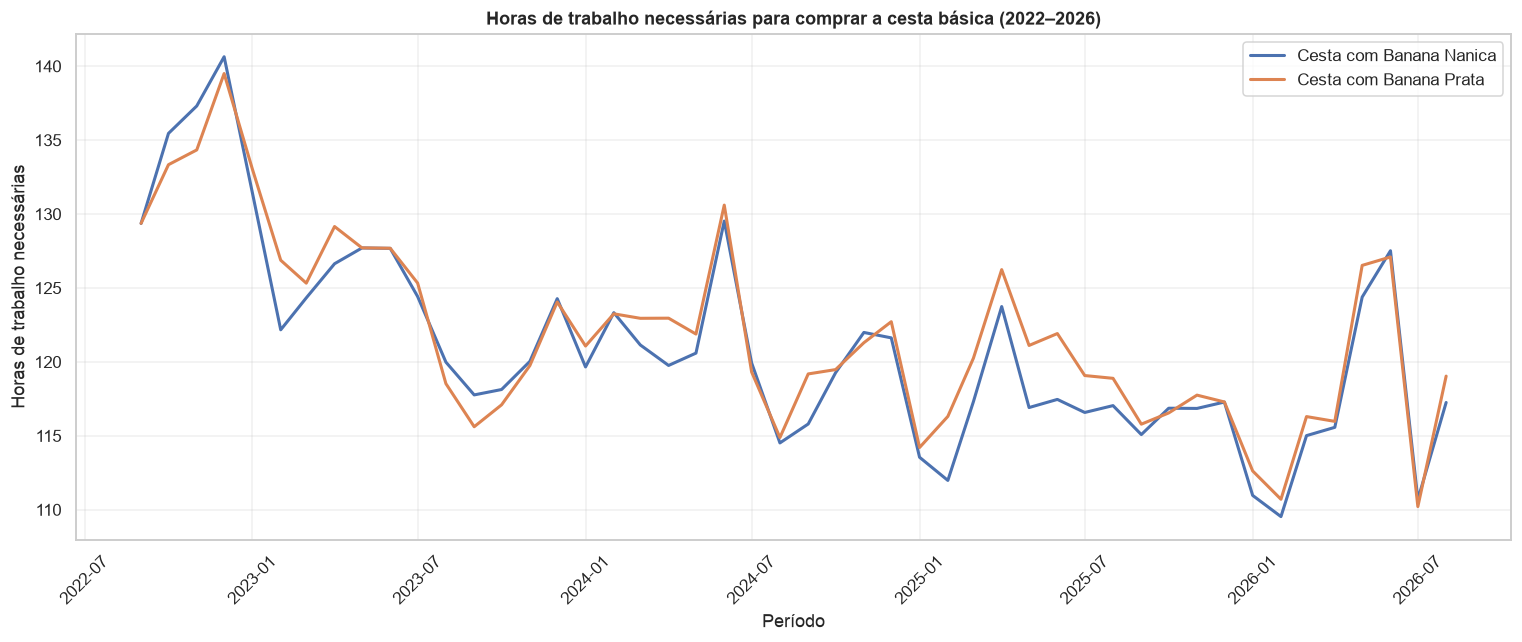

In [30]:
plt.figure(figsize=(14, 6))

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["horas_cesta_banana_nanica"],
    label="Cesta com Banana Nanica",
    linewidth=2
)

plt.plot(
    resultado_cesta["mes"],
    resultado_cesta["horas_cesta_banana_prata"],
    label="Cesta com Banana Prata",
    linewidth=2
)

plt.title(
    "Horas de trabalho necessárias para comprar a cesta básica (2022–2026)",
    fontweight="bold"
)

plt.xlabel("Período")
plt.ylabel("Horas de trabalho necessárias")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Salvar o gráfico
plt.savefig(
    FIG / "horas_trabalho.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Interpretação das horas de trabalho necessárias

O gráfico apresenta uma redução geral na quantidade de
horas de trabalho necessárias para adquirir a cesta básica
entre setembro de 2022 e agosto de 2026.

Os dois cenários apresentam comportamentos semelhantes,
com oscilações ao longo do período e maior necessidade
de horas de trabalho no final de 2022.

Apesar do aumento nominal dos preços da cesta, os reajustes
do salário mínimo permitiram uma melhora relativa na sua
acessibilidade entre o início e o final do período.

Entretanto, a aquisição da cesta ainda exige uma parcela
expressiva da jornada mensal de referência de 220 horas.

O cálculo considera o salário mínimo bruto e não contempla
outras despesas essenciais, como moradia, transporte,
saúde e energia elétrica.

In [31]:
# Criar coluna com o ano
resultado_cesta["ano"] = resultado_cesta["mes"].dt.year

# Definir os cenários
cenarios = {
    "Banana Nanica": {
        "custo": "cesta_banana_nanica",
        "comprometimento": "comprometimento_cesta_banana_nanica",
        "horas": "horas_cesta_banana_nanica"
    },
    "Banana Prata": {
        "custo": "cesta_banana_prata",
        "comprometimento": "comprometimento_cesta_banana_prata",
        "horas": "horas_cesta_banana_prata"
    }
}

# Construir resumo anual
resumos = []

for ano, dados_ano in resultado_cesta.groupby("ano"):

    for nome, colunas in cenarios.items():

        resumos.append({
            "ano": ano,
            "cenario": nome,
            "n_meses": dados_ano["mes"].nunique(),
            "custo_medio": dados_ano[colunas["custo"]].mean(),
            "comprometimento_medio": dados_ano[colunas["comprometimento"]].mean(),
            "horas_medias": dados_ano[colunas["horas"]].mean()
        })

resumo_anual = pd.DataFrame(resumos)

display(resumo_anual.round(2))

,ano,cenario,n_meses,custo_medio,comprometimento_medio,horas_medias
0,2022,Banana Nanica,4,747.52,66.68,135.69
1,2022,Banana Prata,4,738.96,65.91,134.13
2,2023,Banana Nanica,12,738.82,60.79,123.71
3,2023,Banana Prata,12,741.55,61.02,124.18
4,2024,Banana Nanica,12,773.98,59.26,120.59
5,2024,Banana Prata,12,780.64,59.77,121.63
6,2025,Banana Nanica,12,805.35,57.36,116.72
7,2025,Banana Prata,12,819.56,58.37,118.78
8,2026,Banana Nanica,8,857.38,57.18,116.36
9,2026,Banana Prata,8,864.33,57.64,117.31


### Interpretação do resumo anual

Os resultados indicam uma redução no comprometimento
médio do salário líquido e na quantidade média de horas
de trabalho necessárias para adquirir a cesta básica.

Entre 2023 e 2025, anos com cobertura completa, o
comprometimento médio do salário líquido diminuiu:

- Banana Nanica: de 60,79% para 57,36%.
- Banana Prata: de 61,02% para 58,37%.

Apesar do aumento do custo nominal médio da cesta,
houve uma melhora relativa na sua acessibilidade em
relação ao salário mínimo.

É importante destacar que os resultados de 2022
consideram apenas quatro meses, enquanto os de 2026
consideram oito meses. Portanto, as médias desses
anos devem ser interpretadas com cautela, devido
à cobertura parcial e às possíveis variações sazonais.

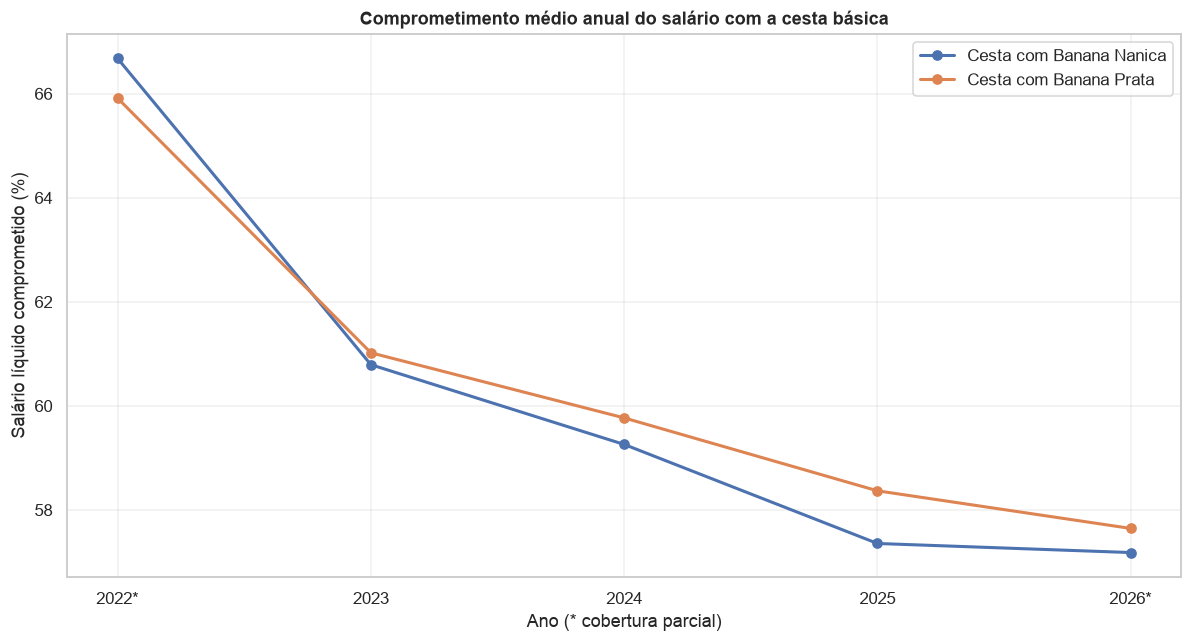

In [32]:
plt.figure(figsize=(11, 6))

for cenario in ["Banana Nanica", "Banana Prata"]:

    dados = resumo_anual[
        resumo_anual["cenario"] == cenario
    ]

    plt.plot(
        dados["ano"],
        dados["comprometimento_medio"],
        marker="o",
        linewidth=2,
        label=f"Cesta com {cenario}"
    )

plt.title(
    "Comprometimento médio anual do salário com a cesta básica",
    fontweight="bold"
)

plt.xlabel("Ano (* cobertura parcial)")
plt.ylabel("Salário líquido comprometido (%)")

plt.xticks(
    [2022, 2023, 2024, 2025, 2026],
    ["2022*", "2023", "2024", "2025", "2026*"]
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Salvar o gráfico
plt.savefig(
    FIG / "comprometimento_anual.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Metodologia e limitações da análise

A análise da acessibilidade da cesta básica foi realizada utilizando os dados mensais de preços por produto, considerando a mediana do preço por quantidade comercializada (PPK) em cada mês. Essa escolha busca reduzir a influência de valores extremos nas observações.

A composição da cesta utilizada como referência foi baseada nas quantidades estabelecidas pelo DIEESE para a Região 1. Os produtos disponíveis na base foram associados aos itens dessa composição, e o custo mensal estimado foi obtido pela multiplicação do PPK mensal pelas respectivas quantidades de referência.

Foram construídos dois cenários para a banana, utilizando separadamente as variedades Nanica e Prata. Para fins de cálculo, foram adotadas estimativas de 13,5 kg para a banana Nanica e 9 kg para a banana Prata, correspondentes às 90 unidades previstas na composição de referência. Esses valores são premissas de cálculo, não pesos médios comprovados pelas observações da base.

Para avaliar a acessibilidade, o custo estimado da cesta foi comparado ao salário mínimo nacional vigente em cada mês. O comprometimento salarial foi calculado com base no salário líquido estimado, enquanto as horas de trabalho necessárias foram calculadas com base no salário mínimo bruto, considerando uma jornada mensal de referência de 220 horas.

**Limitações metodológicas:**

- A composição calculada é uma estimativa baseada nos produtos disponíveis na base, não uma reprodução exata do levantamento oficial do DIEESE.
- A carne bovina Coxão Mole foi utilizada como representante do item carne, constituindo uma aproximação.
- As conversões das quantidades de banana são estimativas adotadas para possibilitar a comparação entre os dois cenários, pois a base não informa o peso médio das unidades comercializadas.
- Para o óleo, foi adotada a conversão estimada de 750 g para aproximadamente 0,813 litro, considerando densidade de referência de 0,922 kg/L.
- A coluna PPK representa o preço dividido pela quantidade comercializada, mas as unidades de referência nem sempre estão explicitadas de forma completa na documentação da base.
- A quantidade de coletas varia entre os produtos e os meses analisados. Essas diferenças podem influenciar a representatividade dos preços medianos mensais, mesmo com a utilização da mediana para reduzir a influência de valores extremos.
- O salário líquido foi estimado considerando desconto previdenciário de 7,5%, sem considerar outros descontos individuais.
- Os anos de 2022 e 2026 possuem períodos incompletos na base, abrangendo quatro e oito meses, respectivamente, o que deve ser considerado nas comparações anuais.

Assim, os resultados devem ser interpretados como uma estimativa da evolução da acessibilidade da cesta básica dentro das condições e limitações dos dados disponíveis.

### Resultados e conclusões

A análise dos dados de setembro de 2022 a agosto de 2026 indica que o custo nominal estimado da cesta básica apresentou uma tendência geral de crescimento, embora tenham ocorrido oscilações ao longo dos meses.

No cenário com banana Nanica, o custo estimado passou de R$ 712,66 para R$ 863,92, representando um aumento nominal de 21,23%. No cenário com banana Prata, passou de R$ 712,70 para R$ 877,06, representando um aumento nominal de 23,06%.

Entretanto, ao comparar o custo estimado da cesta com o salário mínimo vigente em cada período, observou-se uma redução do comprometimento salarial. No cenário da banana Nanica, o indicador passou de 63,57% em setembro de 2022 para 57,62% em agosto de 2026, uma redução de 5,95 pontos percentuais. No cenário da banana Prata, passou de 63,57% para 58,49%, uma redução de 5,08 pontos percentuais.

A quantidade estimada de horas de trabalho necessárias para adquirir a cesta também diminuiu. No cenário Nanica, passou de aproximadamente 129,36 horas para 117,25 horas. No cenário Prata, passou de 129,37 horas para 119,03 horas.

A comparação das médias anuais reforça essa tendência: o comprometimento médio caiu de 66,68% em 2022 para 57,18% em 2026 no cenário Nanica, e de 65,91% para 57,64% no cenário Prata. É importante considerar que 2022 e 2026 possuem períodos incompletos na base, com quatro e oito meses de observação, respectivamente.

Também foram identificadas oscilações relevantes nos preços de determinados produtos. Entre junho e julho de 2026, as medianas de preço do tomate, da batata e da carne bovina Coxão Mole apresentaram reduções de 47,82%, 39,49% e 10,81%, respectivamente. Essas reduções contribuíram para a diminuição do custo estimado da cesta naquele período.

A investigação dos registros individuais confirmou a redução das medianas desses produtos. Entretanto, também foi observada uma diminuição na quantidade de coletas, sendo necessário considerar possíveis diferenças na composição das amostras entre os meses. Os dados não permitem determinar as causas econômicas dessas reduções.

Portanto, considerando os dados disponíveis e as aproximações adotadas, os resultados sugerem que a cesta básica se tornou relativamente mais acessível em relação ao salário mínimo entre setembro de 2022 e agosto de 2026. Isso não significa que os alimentos ficaram mais baratos, mas que o custo estimado da cesta passou a representar uma parcela menor da remuneração mínima.

Apesar dessa melhora relativa, a aquisição da cesta ainda compromete mais da metade do salário mínimo líquido estimado ao final do período, indicando um peso significativo da alimentação no orçamento de um trabalhador que recebe essa remuneração.

Por fim, é importante ressaltar que os resultados representam estimativas, sujeitas às limitações da base de dados, às aproximações na correspondência dos produtos e às conversões de unidades utilizadas, especialmente nos cenários de banana e na conversão do óleo.